# Can TeddyWorld Cut Its Marketing Budget in Half? A Pareto Analysis of Traffic Sources

**Author:** Pham Hong Hieu (Haven) · **Data:** `orders.csv` (32,313 orders) and `website_sessions.csv` (472,871 sessions),
an online retailer of stuffed toys, 2012–2015

## The brief

The CEO of TeddyWorld, an online teddy-bear retailer, wants to cut the advertising budget by 50% and asks three
questions:

1. Which traffic source generates the most revenue?
2. How many sources together produce about 80% of revenue?
3. Is there enough evidence to recommend where the 50% cut should fall?

The Pareto principle suggests that a small number of sources drive most of the revenue. This notebook tests that
claim on the data. It also tests what the data **cannot** tell us, because order data alone contain no advertising
cost.

**Workflow:** load → audit and clean → join orders to sessions → Pareto → complementary metrics → answers and a
decision plan.

## 1. Setup and data loading

Only the columns the analysis needs are read, which keeps memory use low on a 470,000-row session table.

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

TEAL, CRIMSON, AMBER, SLATE, INK = "#087F8C", "#C8374D", "#E5A12B", "#B9C4CF", "#263345"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.edgecolor": "#B8C4CE", "axes.labelcolor": INK, "text.color": INK,
                     "grid.color": "#E6EBEF", "figure.dpi": 110})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
orders_raw = pd.read_csv(
    DATA_DIR / "orders.csv",
    usecols=["order_id", "website_session_id", "price_usd", "cogs_usd"],
    dtype={"order_id": "string", "website_session_id": "string"},
)
sessions_raw = pd.read_csv(
    DATA_DIR / "website_sessions.csv.gz",
    usecols=["website_session_id", "utm_source", "utm_campaign", "http_referer"],
    dtype={"website_session_id": "string"},
)
print(f"Orders: {len(orders_raw):,} rows | Sessions: {len(sessions_raw):,} rows")
display(orders_raw.head(3), sessions_raw.head(3))

Orders: 32,313 rows | Sessions: 472,871 rows


,order_id,website_session_id,price_usd,cogs_usd
0,1,20,49.99,19.49
1,2,104,49.99,19.49
2,3,147,49.99,19.49


,website_session_id,utm_source,utm_campaign,http_referer
0,1,gsearch,nonbrand,https://www.gsearch.com
1,2,gsearch,nonbrand,https://www.gsearch.com
2,3,gsearch,nonbrand,https://www.gsearch.com


## 2. Data audit and cleaning

**Rule:** each `order_id` is one order and each `website_session_id` is one session. If an ID appears with conflicting
records, the notebook stops with an error instead of silently doubling revenue during the join.

**Convention from the brief:** a session with no `utm_source` counts as *Organic*. Section 6 shows that this
label combines two very different kinds of traffic.

In [3]:
print("Missing values in orders:")
display(orders_raw.isna().sum().rename("missing").to_frame().T)
print("Missing values in sessions:")
display(sessions_raw.isna().sum().rename("missing").to_frame().T)
print("Duplicated order rows:", int(orders_raw.duplicated().sum()))
print("Duplicated session rows:", int(sessions_raw.duplicated().sum()))

Missing values in orders:


,order_id,website_session_id,price_usd,cogs_usd
missing,0,0,0,0


Missing values in sessions:


,website_session_id,utm_source,utm_campaign,http_referer
missing,0,83328,83328,39917


Duplicated order rows:

 0


Duplicated session rows: 0


In [4]:
orders = orders_raw.drop_duplicates().copy()
sessions = sessions_raw.drop_duplicates().copy()

if orders["order_id"].duplicated().any():
    raise ValueError("order_id is not unique; resolve duplicates before computing revenue.")
if sessions["website_session_id"].duplicated().any():
    raise ValueError("website_session_id is not unique; the join would duplicate orders.")

orders["price_usd"] = pd.to_numeric(orders["price_usd"], errors="coerce")
if (orders["price_usd"].dropna() < 0).any():
    raise ValueError("Negative revenue found; check how refunds are recorded.")
orders = orders.dropna(subset=["price_usd"])

sessions["utm_source"] = sessions["utm_source"].astype("string").str.strip()
sessions["utm_source"] = sessions["utm_source"].mask(sessions["utm_source"].fillna("").eq(""), "Organic")
print(f"After cleaning: {len(orders):,} orders, {len(sessions):,} sessions")
print("Sessions labelled Organic:", f"{(sessions['utm_source'] == 'Organic').sum():,}")

After cleaning: 32,313 orders, 472,871 sessions
Sessions labelled Organic: 83,328


## 3. Joining orders to sessions

A **left join** keeps every order, and `validate="many_to_one"` enforces one session per order key. Orders that do
not match a session are labelled *Unmatched* and kept separate rather than counted as Organic.

In [5]:
marketing = orders.merge(
    sessions[["website_session_id", "utm_source", "utm_campaign", "http_referer"]],
    on="website_session_id", how="left", validate="many_to_one", indicator=True,
)
marketing["source"] = marketing["utm_source"].fillna("Organic")
marketing.loc[marketing["_merge"].eq("left_only"), "source"] = "Unmatched"

assert len(marketing) == len(orders), "The join changed the number of orders."
assert np.isclose(marketing["price_usd"].sum(), orders["price_usd"].sum())
print(f"Orders after join: {len(marketing):,}")
print(f"Orders without a matching session: {int(marketing['_merge'].eq('left_only').sum()):,}")
print(f"Total revenue: ${marketing['price_usd'].sum():,.2f}")

Orders after join: 32,313
Orders without a matching session: 0
Total revenue: $1,938,509.75


## 4. Pareto analysis by traffic source

Revenue here is **order revenue** (`price_usd`), before refunds and before any marketing cost.

1. Sum revenue by source and sort in descending order.
2. Compute each source's share and the cumulative share.
3. The 80% group **includes** the source whose cumulative share first reaches or passes 80%.

In [6]:
pareto = (
    marketing.groupby("source", as_index=False)
    .agg(revenue_usd=("price_usd", "sum"), orders=("order_id", "nunique"))
    .sort_values("revenue_usd", ascending=False, ignore_index=True)
)
total_revenue = pareto["revenue_usd"].sum()
pareto["share_pct"] = pareto["revenue_usd"] / total_revenue * 100
pareto["cum_pct"] = pareto["share_pct"].cumsum().clip(upper=100)

cutoff_idx = int(np.flatnonzero(pareto["cum_pct"].to_numpy() >= 80)[0])
n_80, n_sources = cutoff_idx + 1, len(pareto)
pareto["group"] = np.where(pareto.index <= cutoff_idx, "Top 80% of revenue", "Remainder")
n_top_20 = max(1, math.ceil(n_sources * 0.20))
top_20_share = pareto.head(n_top_20)["share_pct"].sum()

print(f"{n_80} of {n_sources} sources ({n_80 / n_sources:.0%}) produce {pareto.loc[cutoff_idx, 'cum_pct']:.1f}% of revenue")
print(f"The top {n_top_20} source(s) (20% of sources, rounded up) produce {top_20_share:.1f}% of revenue")
pareto.to_csv(TABLE_DIR / "pareto_by_source.csv", index=False)
pareto

2 of 4 sources (50%) produce 85.0% of revenue
The top 1 source(s) (20% of sources, rounded up) produce 65.8% of revenue


,source,revenue_usd,orders,share_pct,cum_pct,group
0,gsearch,"1,276,144.89",21333,65.83,65.83,Top 80% of revenue
1,Organic,"371,433.03",6118,19.16,84.99,Top 80% of revenue
2,bsearch,"268,672.50",4519,13.86,98.85,Remainder
3,socialbook,"22,259.33",343,1.15,100.00,Remainder


## 5. The Pareto chart

Teal bars belong to the group that reaches 80%. The amber bar is the untagged (*Organic*) traffic, and grey bars are
the remainder. The red line is cumulative revenue share, and the dashed line marks the 80% threshold.

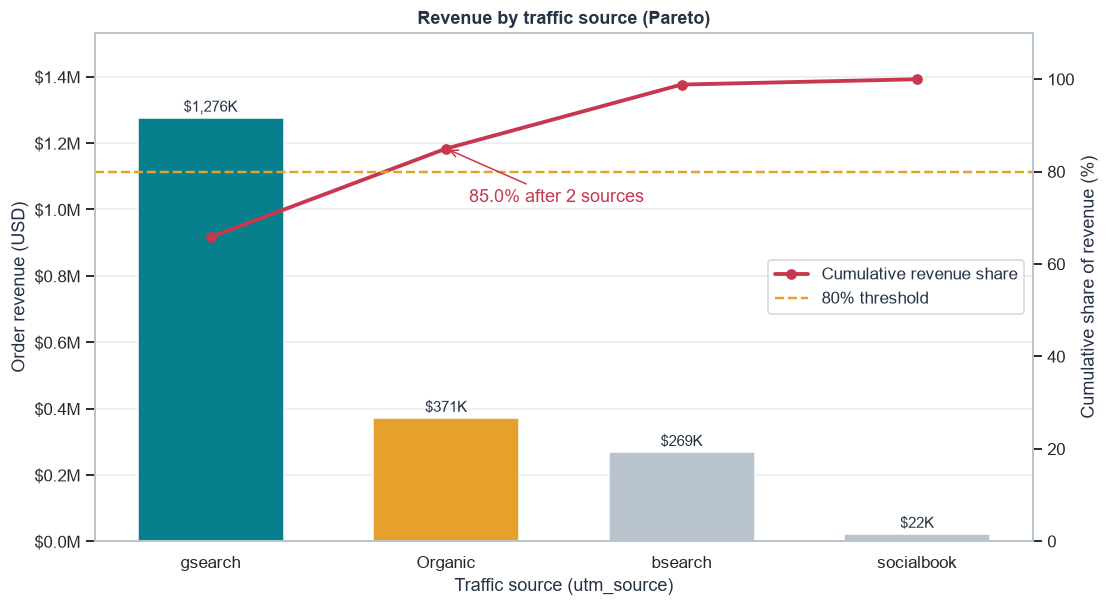

In [7]:
fig, ax1 = plt.subplots(figsize=(11, 6))
x = np.arange(n_sources)
colours = [AMBER if s == "Organic" else (TEAL if i <= cutoff_idx else SLATE) for i, s in enumerate(pareto["source"])]
bars = ax1.bar(x, pareto["revenue_usd"], color=colours, width=0.62)
for bar, value in zip(bars, pareto["revenue_usd"]):
    ax1.annotate(f"${value / 1e3:,.0f}K", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10)
ax1.set_xticks(x, pareto["source"])
ax1.set_ylabel("Order revenue (USD)")
ax1.set_xlabel("Traffic source (utm_source)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1e6:.1f}M"))
ax1.set_ylim(0, pareto["revenue_usd"].max() * 1.2)
ax1.grid(axis="x", visible=False)

ax2 = ax1.twinx()
ax2.plot(x, pareto["cum_pct"], color=CRIMSON, marker="o", linewidth=2.5, label="Cumulative revenue share")
ax2.axhline(80, color=AMBER, linestyle="--", linewidth=1.6, label="80% threshold")
ax2.set_ylim(0, 110)
ax2.set_ylabel("Cumulative share of revenue (%)")
ax2.grid(False)
ax2.annotate(f"{pareto.loc[cutoff_idx, 'cum_pct']:.1f}% after {n_80} sources",
             (cutoff_idx, pareto.loc[cutoff_idx, "cum_pct"]), xytext=(15, -35), textcoords="offset points",
             color=CRIMSON, arrowprops=dict(arrowstyle="->", color=CRIMSON))
ax2.legend(loc="center right")
ax1.set_title("Revenue by traffic source (Pareto)", fontweight="bold")
save(fig, "01_pareto_by_source")
plt.show()

## 6. What "Organic" really contains

The brief treats every untagged session as Organic. The `http_referer` field can split that group:

- **Organic search**: no paid tag, but the visitor came from a search engine.
- **Direct type-in**: no paid tag and no referrer. The visitor typed the address or used a bookmark.

Neither group is bought with ad spend, so neither can be cut. They are separated here because they behave
differently and because direct traffic reflects brand strength.

In [8]:
def channel(row):
    if row["source"] != "Organic":
        return row["source"]
    return "organic search" if pd.notna(row["http_referer"]) else "direct type-in"

marketing["channel"] = marketing.apply(channel, axis=1)
channel_view = (
    marketing.groupby("channel", as_index=False)
    .agg(revenue_usd=("price_usd", "sum"), orders=("order_id", "nunique"))
    .sort_values("revenue_usd", ascending=False, ignore_index=True)
)
channel_view["share_pct"] = channel_view["revenue_usd"] / channel_view["revenue_usd"].sum() * 100
channel_view["paid"] = ~channel_view["channel"].isin(["organic search", "direct type-in"])
channel_view.to_csv(TABLE_DIR / "revenue_by_channel.csv", index=False)
channel_view

,channel,revenue_usd,orders,share_pct,paid
0,gsearch,"1,276,144.89",21333,65.83,True
1,bsearch,"268,672.50",4519,13.86,True
2,organic search,"196,809.19",3262,10.15,False
3,direct type-in,"174,623.84",2856,9.01,False
4,socialbook,"22,259.33",343,1.15,True


## 7. Beyond revenue: sessions, conversion and order value

A source can lead on revenue simply because it brings the most visitors. The next table adds traffic volume,
**session conversion rate** (sessions with at least one order ÷ all sessions) and **average order value**.

In [9]:
sessions_by_source = (sessions.groupby("utm_source", as_index=False)
                      .agg(sessions=("website_session_id", "nunique"))
                      .rename(columns={"utm_source": "source"}))
buying_sessions = (marketing[marketing["_merge"].eq("both")]
                   .groupby("source", as_index=False)
                   .agg(buying_sessions=("website_session_id", "nunique")))
performance = (pareto[["source", "orders", "revenue_usd"]]
               .merge(sessions_by_source, on="source", how="left", validate="one_to_one")
               .merge(buying_sessions, on="source", how="left", validate="one_to_one"))
performance["conversion_pct"] = performance["buying_sessions"] / performance["sessions"] * 100
performance["aov_usd"] = performance["revenue_usd"] / performance["orders"]
performance["revenue_per_session"] = performance["revenue_usd"] / performance["sessions"]
performance.to_csv(TABLE_DIR / "source_performance.csv", index=False)
performance

,source,orders,revenue_usd,sessions,buying_sessions,conversion_pct,aov_usd,revenue_per_session
0,gsearch,21333,"1,276,144.89",316035,21333,6.75,59.82,4.04
1,Organic,6118,"371,433.03",83328,6118,7.34,60.71,4.46
2,bsearch,4519,"268,672.50",62823,4519,7.19,59.45,4.28
3,socialbook,343,"22,259.33",10685,343,3.21,64.90,2.08


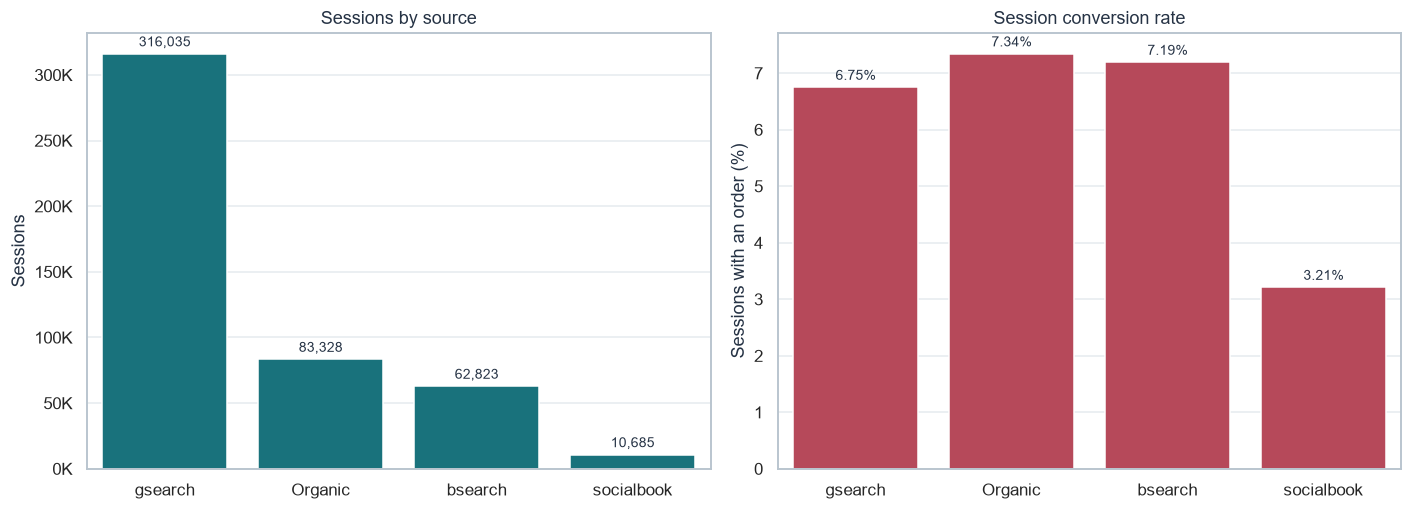

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order = performance["source"]
sns.barplot(data=performance, x="source", y="sessions", order=order, color=TEAL, ax=axes[0])
axes[0].set(title="Sessions by source", xlabel="", ylabel="Sessions")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}K"))
sns.barplot(data=performance, x="source", y="conversion_pct", order=order, color=CRIMSON, ax=axes[1])
axes[1].set(title="Session conversion rate", xlabel="", ylabel="Sessions with an order (%)")
for ax, fmt in [(axes[0], "{:,.0f}"), (axes[1], "{:.2f}%")]:
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues], padding=3, fontsize=9)
fig.tight_layout()
save(fig, "02_sessions_and_conversion")
plt.show()

`gsearch` leads on revenue because of **volume**: it brings two thirds of all sessions, but its conversion rate
(6.8%) is slightly below `bsearch` (7.2%) and untagged traffic (7.3%). Average order value is about $60 everywhere.
The clear outlier is `socialbook`. It converts at 3.2%, about half the rate of the other sources, and earns about
$2 per session against $4 or more elsewhere.

## 8. Gross margin before advertising

`orders.csv` includes product cost (`cogs_usd`), so gross profit **before marketing** can be computed by source. This
is still not ROI or ROAS, because advertising spend is not in the data.

In [11]:
marketing["gross_profit"] = marketing["price_usd"] - marketing["cogs_usd"]
margin = (marketing.groupby("source", as_index=False)
          .agg(revenue_usd=("price_usd", "sum"), gross_profit_usd=("gross_profit", "sum")))
margin["gross_margin_pct"] = margin["gross_profit_usd"] / margin["revenue_usd"] * 100
margin.sort_values("revenue_usd", ascending=False).to_csv(TABLE_DIR / "gross_margin_by_source.csv", index=False)
margin.sort_values("revenue_usd", ascending=False)

,source,revenue_usd,gross_profit_usd,gross_margin_pct
2,gsearch,"1,276,144.89","800,158.50",62.70
0,Organic,"371,433.03","233,444.50",62.85
1,bsearch,"268,672.50","168,434.00",62.69
3,socialbook,"22,259.33","14,102.50",63.36


Gross margin is almost identical across sources (about 63%), because every channel sells the same product mix at
the same prices. Margin therefore does not separate the channels. The budget decision depends entirely on what each
channel costs to run.

## 9. Answers for the CEO

In [12]:
leader = pareto.iloc[0]
top_group = pareto.head(n_80)
gsearch_nonbrand = marketing.query("source == 'gsearch' and utm_campaign == 'nonbrand'")["price_usd"].sum()
paid_sources = pareto.loc[~pareto["source"].isin(["Organic", "Unmatched"]), "source"].tolist()

print("Q1. Largest revenue source")
print(f"    {leader['source']}: ${leader['revenue_usd']:,.0f} ({leader['share_pct']:.1f}% of revenue)")
print(f"    of which the gsearch non-brand campaign alone: ${gsearch_nonbrand:,.0f} "
      f"({gsearch_nonbrand / total_revenue:.1%})")
print()
print("Q2. Sources that reach 80% of revenue")
print(f"    {n_80} of {n_sources}: {', '.join(top_group['source'])} -> {top_group['share_pct'].sum():.1f}% of revenue")
print()
print("Q3. Can we choose where to cut 50%?")
print(f"    Not yet. The paid sources are {', '.join(paid_sources)}, but ad spend by source is not in the data,")
print("    so revenue per dollar of spend (ROAS) cannot be calculated.")

Q1. Largest revenue source
    gsearch: $1,276,145 (65.8% of revenue)
    of which the gsearch non-brand campaign alone: $1,124,414 (58.0%)

Q2. Sources that reach 80% of revenue
    2 of 4: gsearch, Organic -> 85.0% of revenue

Q3. Can we choose where to cut 50%?
    Not yet. The paid sources are gsearch, bsearch, socialbook, but ad spend by source is not in the data,
    so revenue per dollar of spend (ROAS) cannot be calculated.


### Q3 in detail: a decision plan for the 50% cut

**What the data show.** Revenue is concentrated. `gsearch` alone produces about two thirds of it, and its non-brand
campaign alone produces 58%. With untagged traffic added, the top two sources pass 80%. Among the smaller paid
sources, `bsearch` converts as well as `gsearch`, while `socialbook` converts at half the rate and earns half the
revenue per session.

**What the data cannot show.** Without spend by source, a small revenue share may still be efficient, and a large
one may be expensive. Untagged traffic is not a budget line at all, so it cannot be "cut".

**Recommended path to the decision:**

1. Pull ad spend by `utm_source` and `utm_campaign` for the same period.
2. Rank campaigns by ROAS and by gross profit before ads, and look at incremental rather than total revenue.
3. Cut in stages, starting with the weakest campaigns. On current evidence `socialbook` is the first candidate:
   it has the lowest conversion and revenue per session and only 1.1% of revenue at stake. Track the effect on
   orders before reaching 50%, because paid search also feeds brand searches and direct visits.
4. Protect the `gsearch` non-brand campaign until the test shows its incremental return. It is the single largest
   revenue engine.

In [13]:
budget_template = pd.DataFrame({"source": paid_sources, "ad_spend_usd": np.nan})
print("Ad spend template. Fill in actual spend to compute ROAS; no values are assumed.")
budget_template

Ad spend template. Fill in actual spend to compute ROAS; no values are assumed.


,source,ad_spend_usd
0,gsearch,NaN
1,bsearch,NaN
2,socialbook,NaN


## 10. Summary

- Every order was kept through the join, with checks that revenue was not duplicated.
- Untagged traffic follows the brief's Organic convention and is then split into organic search and direct type-in.
- The Pareto result and the conversion, order-value and margin views all point to the same conclusion. Revenue
  is concentrated in `gsearch`, but a budget cut must be decided on spend efficiency, which needs cost data the order
  file does not contain.

**Scope.** Revenue is the sum of `price_usd` in `orders.csv`, before refunds and before marketing cost.